# 24 - Reality check: the model vs the bookmakers (P8-02)

Betting every game at average odds loses 2.8%. Before trying selective
strategies (P8-03..05), this notebook asks where, if anywhere, the model knows
something the market doesn't. A strategy can only make money long-term where
the model's probabilities beat the de-margined odds.

- **Data:** `data/processed/oos_predictions.csv` from P8-01: walk-forward
  probabilities for the 7 domestic leagues, 22-23..25-26 (9,530 matches) plus
  26-27 to date, shown separately.
- **Market:** `q` = de-margined (proportional) Pinnacle opening prices, falling
  back to the market average opening prices where Pinnacle is missing (most of
  late 25-26 and all of 26-27).
- **Statistics (plan §5):** log loss; paired bootstrap of per-match
  differences, 5,000 resamples, seed 42. Differences are **model - market**, so
  negative means the model is better. Blend weights are tuned on 22-23/23-24
  and reported on 24-25/25-26.

In [1]:
import os
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize, minimize_scalar
from sklearn.linear_model import LogisticRegression

from betting.market import proportional
from betting.simulate import flat_argmax, load_oos, simulate, single, summarise
from evaluate import better, paired_bootstrap
from load_data import read_matches

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

TEST = ["22-23", "23-24", "24-25", "25-26"]
TUNE, REPORT = TEST[:2], TEST[2:]
CURRENT = "26-27"
OUTCOMES = ["H", "D", "A"]

# Chart colours: model = categorical slot 1, market = slot 2
MODEL_COLOUR, MARKET_COLOUR = "#2a78d6", "#eb6834"

## Data

Gameweek and promoted teams come from `all_matches.csv`. A team is *promoted*
when it wasn't in the same league the season before (21-22 is in the file, so
22-23 is covered).

In [2]:
oos = load_oos()
oos = oos[oos["FTR"].notna()].reset_index(drop=True)

matches = read_matches()
oos = oos.merge(
    matches[["Season", "Div", "HomeTeam", "AwayTeam", "Gameweek"]],
    on=["Season", "Div", "HomeTeam", "AwayTeam"], how="left", validate="one_to_one",
)

seasons = sorted(matches["Season"].unique())
previous = dict(zip(seasons[1:], seasons[:-1]))
in_league = set(zip(matches["Div"], matches["Season"], matches["HomeTeam"]))
for side in ["Home", "Away"]:
    oos[f"{side}Promoted"] = [
        (div, previous[season], team) not in in_league
        for div, season, team in zip(oos["Div"], oos["Season"], oos[f"{side}Team"])
    ]
oos["Promoted"] = oos["HomePromoted"] | oos["AwayPromoted"]

# Outcome index in H, D, A order
y = oos["FTR"].map({"H": 0, "D": 1, "A": 2}).to_numpy()
P = oos[["pH", "pD", "pA"]].to_numpy()
Q = oos[["qH", "qD", "qA"]].to_numpy()                                        # Pinnacle -> Avg, opening
Q_AVG = proportional(oos[["AvgH", "AvgD", "AvgA"]].to_numpy())                 # Avg only, opening
Q_CLOSE = oos[["qcH", "qcD", "qcA"]].to_numpy()                               # Pinnacle -> Avg, closing

main = oos["Season"].isin(TEST).to_numpy()
tune = oos["Season"].isin(TUNE).to_numpy()
report = oos["Season"].isin(REPORT).to_numpy()
current = (oos["Season"] == CURRENT).to_numpy()

def ll(proba, outcome=y):
    return -np.log(np.clip(proba[np.arange(len(outcome)), outcome], 1e-15, 1))

LL_MODEL, LL_MARKET = ll(P), ll(Q)

print(f"{main.sum()} matches 22-23..25-26, {current.sum()} in 26-27 to date")
print("Promoted teams in", int(oos.loc[main, "Promoted"].sum()), "main-period matches")
print(oos.groupby("Season")["qSource"].value_counts().unstack(fill_value=0))

9530 matches 22-23..25-26, 641 in 26-27 to date
Promoted teams in 2664 main-period matches
qSource   avg  pinnacle
Season                 
22-23       0      2438
23-24       1      2363
24-25       0      2364
25-26    1167      1197
26-27     641         0


## 1. Log loss: model vs market

`compare` scores the model against a reference on a set of matches and
bootstraps the per-match difference.

In [3]:
def compare(mask, reference=Q, candidate=P, outcome=y):
    model, market = ll(candidate[mask], outcome[mask]), ll(reference[mask], outcome[mask])
    boot = paired_bootstrap(model - market)
    return {
        "n": int(mask.sum()),
        "model": model.mean(),
        "market": market.mean(),
        "diff": boot["mean"],
        "ci_low": boot["ci"][0],
        "ci_high": boot["ci"][1],
        "p_model_better": boot["p_better"],
    }

def table(rows):
    return pd.DataFrame(rows).T.round(4).astype({"n": int})

overall = table({
    "22-23..25-26 vs Pinnacle->Avg opening": compare(main),
    "22-23..25-26 vs Avg opening": compare(main, Q_AVG),
    "22-23..25-26 vs Pinnacle->Avg closing": compare(main, Q_CLOSE),
    "tune 22-23/23-24": compare(tune),
    "report 24-25/25-26": compare(report),
    "26-27 to date (Avg opening)": compare(current),
})
overall

,n,model,market,diff,ci_low,ci_high,p_model_better
22-23..25-26 vs Pinnacle->Avg opening,9530,0.9779,0.9568,0.0211,0.0174,0.0249,0.00
22-23..25-26 vs Avg opening,9530,0.9779,0.9574,0.0206,0.0168,0.0242,0.00
22-23..25-26 vs Pinnacle->Avg closing,9530,0.9779,0.9534,0.0246,0.0206,0.0285,0.00
tune 22-23/23-24,4802,0.9697,0.9503,0.0194,0.0142,0.0247,0.00
report 24-25/25-26,4728,0.9864,0.9634,0.0229,0.0174,0.0284,0.00
26-27 to date (Avg opening),641,0.9770,0.9623,0.0147,-0.0007,0.0305,0.03


In [4]:
by_league = table({div: compare(main & (oos["Div"] == div).to_numpy()) for div in sorted(oos["Div"].unique())})
by_league

,n,model,market,diff,ci_low,ci_high,p_model_better
D1,1224,0.9918,0.9710,0.0208,0.0096,0.0319,0.0002
E0,1520,0.9800,0.9652,0.0148,0.0047,0.0251,0.0020
F1,1298,0.9979,0.9785,0.0194,0.0098,0.0294,0.0000
I1,1520,0.9920,0.9694,0.0226,0.0135,0.0318,0.0000
N1,1224,0.9548,0.9382,0.0166,0.0053,0.0281,0.0012
P1,1224,0.9381,0.9065,0.0316,0.0215,0.0415,0.0000
SP1,1520,0.9844,0.9613,0.0231,0.0144,0.0321,0.0000


In [5]:
by_season = table({s: compare((oos["Season"] == s).to_numpy()) for s in TEST + [CURRENT]})
by_season

,n,model,market,diff,ci_low,ci_high,p_model_better
22-23,2438,0.9752,0.9580,0.0172,0.0095,0.0250,0.00
23-24,2364,0.9640,0.9423,0.0217,0.0141,0.0293,0.00
24-25,2364,0.9796,0.9574,0.0223,0.0145,0.0298,0.00
25-26,2364,0.9931,0.9695,0.0236,0.0161,0.0309,0.00
26-27,641,0.9770,0.9623,0.0147,-0.0007,0.0305,0.03


In [6]:
# Model - market log loss per league and season (point estimates)
grid = (
    oos.assign(diff=LL_MODEL - LL_MARKET)
    .pivot_table(index="Div", columns="Season", values="diff", aggfunc="mean")
    .round(4)
)
grid

Season,22-23,23-24,24-25,25-26,26-27
Div,,,,,
D1,0.0084,0.0262,0.0351,0.0134,-0.0005
E0,0.0041,0.0287,0.0129,0.0135,0.0172
F1,0.0162,0.0120,0.0152,0.0350,0.0450
I1,0.0213,0.0224,0.0213,0.0254,-0.0023
N1,0.0075,0.0144,0.0204,0.0240,-0.0015
P1,0.0377,0.0394,0.0253,0.0239,-0.0220
SP1,0.0255,0.0097,0.0270,0.0301,0.0608


### Per outcome

One-vs-rest binary log loss for each outcome (e.g. "home win or not"), so we
can see whether the model's deficit is in home, draw or away probabilities.

In [7]:
def binary_ll(p, hit):
    p = np.clip(p, 1e-15, 1 - 1e-15)
    return -(hit * np.log(p) + (1 - hit) * np.log(1 - p))

def compare_outcome(mask, k, reference=Q):
    hit = (y[mask] == k).astype(float)
    model, market = binary_ll(P[mask, k], hit), binary_ll(reference[mask, k], hit)
    boot = paired_bootstrap(model - market)
    return {"n": int(mask.sum()), "model": model.mean(), "market": market.mean(),
            "diff": boot["mean"], "ci_low": boot["ci"][0], "ci_high": boot["ci"][1]}

per_outcome = table({
    f"{o} {label}": compare_outcome(mask, k)
    for label, mask in [("22-23..25-26", main), ("report", report)]
    for k, o in enumerate(OUTCOMES)
})
per_outcome

,n,model,market,diff,ci_low,ci_high
H 22-23..25-26,9530,0.6103,0.5949,0.0153,0.0122,0.0184
D 22-23..25-26,9530,0.5604,0.5534,0.0069,0.0048,0.0089
A 22-23..25-26,9530,0.5463,0.5336,0.0127,0.0097,0.0156
H report,4728,0.6123,0.5949,0.0174,0.0130,0.0219
D report,4728,0.5645,0.5572,0.0073,0.0045,0.0100
A report,4728,0.5530,0.5407,0.0123,0.0081,0.0165


## 2. Calibration

Reliability curves (10 equal-count bins of predicted probability) per outcome,
22-23..25-26. Points below the diagonal at the right of a panel are
over-confidence: the source said more likely than it turned out.

The **calibration slope** is the coefficient of a logistic regression of the
outcome on logit(p). 1 = well calibrated; below 1 = over-confident (too
spread out); above 1 = under-confident.

In [8]:
def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

def calibration_slope(p, hit):
    fit = LogisticRegression(C=1e6).fit(logit(p).reshape(-1, 1), hit)
    return fit.coef_[0, 0], fit.intercept_[0]

rows = {}
for k, o in enumerate(OUTCOMES):
    hit = (y[main] == k).astype(int)
    for name, probs in [("model", P), ("market", Q)]:
        slope, intercept = calibration_slope(probs[main, k], hit)
        rows[(o, name)] = {"mean p": probs[main, k].mean(), "actual": hit.mean(),
                           "slope": slope, "intercept": intercept}
pd.DataFrame(rows).T.round(3)

mean p  actual  slope  intercept
H model    0.432   0.439  1.040      0.041
  market   0.441   0.439  1.129      0.015
D model    0.247   0.250  1.600      0.686
  market   0.244   0.250  1.089      0.133
A model    0.321   0.311  0.998     -0.058
  market   0.315   0.311  1.168      0.090

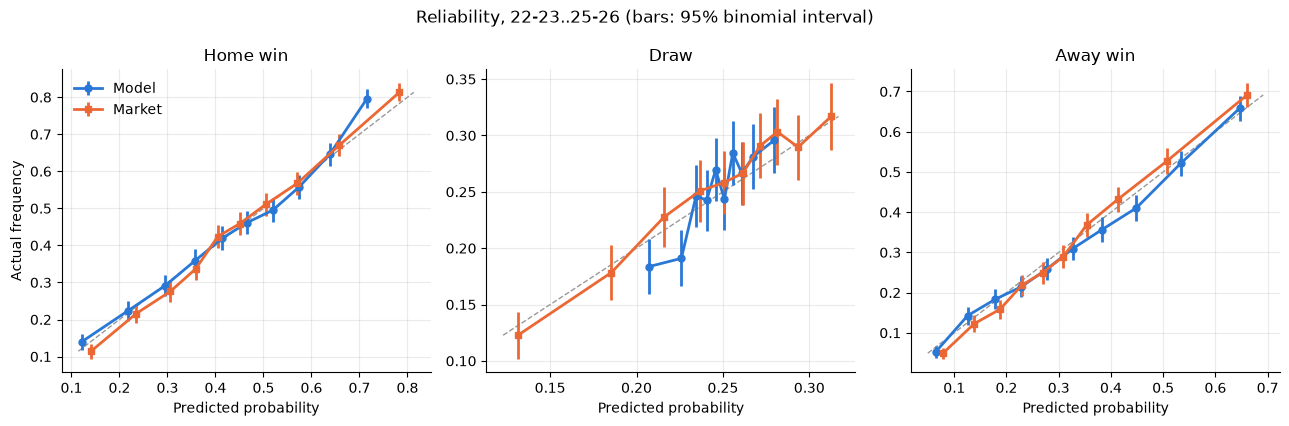

In [9]:
def reliability(p, hit, bins=10):
    frame = pd.DataFrame({"p": p, "hit": hit})
    frame["bin"] = pd.qcut(frame["p"], bins, labels=False, duplicates="drop")
    out = frame.groupby("bin").agg(p=("p", "mean"), actual=("hit", "mean"), n=("hit", "size"))
    out["se"] = np.sqrt(out["actual"] * (1 - out["actual"]) / out["n"])
    return out

fig, axes = plt.subplots(1, 3, figsize=(13, 4.3), sharey=False)
for ax, (k, o) in zip(axes, enumerate(OUTCOMES)):
    hit = (y[main] == k).astype(int)
    lo, hi = 1, 0
    for name, probs, colour, marker in [("Model", P, MODEL_COLOUR, "o"), ("Market", Q, MARKET_COLOUR, "s")]:
        rel = reliability(probs[main, k], hit)
        ax.errorbar(rel["p"], rel["actual"], yerr=1.96 * rel["se"], color=colour, marker=marker,
                    markersize=5, linewidth=2, capsize=0, label=name)
        lo, hi = min(lo, rel["p"].min(), rel["actual"].min()), max(hi, rel["p"].max(), rel["actual"].max())
    ax.plot([lo, hi], [lo, hi], color="#999999", linewidth=1, linestyle="--", zorder=0)
    ax.set_title({"H": "Home win", "D": "Draw", "A": "Away win"}[o])
    ax.set_xlabel("Predicted probability")
    ax.grid(alpha=0.25)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
axes[0].set_ylabel("Actual frequency")
axes[0].legend(frameon=False)
fig.suptitle("Reliability, 22-23..25-26 (bars: 95% binomial interval)")
fig.tight_layout()
plt.show()

In [10]:
# Where the model is furthest from reality, per outcome: bins with |predicted - actual| > 3pp
rows = []
for k, o in enumerate(OUTCOMES):
    hit = (y[main] == k).astype(int)
    for name, probs in [("model", P), ("market", Q)]:
        rel = reliability(probs[main, k], hit)
        rel["gap"] = rel["p"] - rel["actual"]
        for _, r in rel[rel["gap"].abs() > 0.03].iterrows():
            rows.append({"outcome": o, "source": name, "mean p": r["p"], "actual": r["actual"],
                         "gap": r["gap"], "n": int(r["n"]),
                         "significant": abs(r["gap"]) > 1.96 * r["se"]})
pd.DataFrame(rows).round(3)

,outcome,source,mean p,actual,gap,n,significant
0,H,model,0.715,0.795,-0.080,953,True
1,H,market,0.306,0.276,0.030,953,True
2,H,market,0.783,0.813,-0.030,953,True
3,D,model,0.226,0.191,0.035,953,True
4,A,model,0.448,0.410,0.038,953,True
5,A,market,0.661,0.692,-0.031,953,True


## 3. Blend test

Does the model add anything to the market's probabilities? Three combinations,
fitted on the tuning seasons by minimising log loss, scored on the report
seasons:

- **market power** `p ∝ q^b` - market only, recalibrated (a control: any gain
  here is the favourite-longshot bias, not model information);
- **log pool** `p ∝ p_model^a · q^b`;
- **linear pool** `w·p_model + (1-w)·q`.

If the log pool beats the market (and the market-power control) on the report
seasons with CI upper < 0, the model carries information the market lacks.

In [11]:
def normalise_log(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def log_pool(a, b, p=P, q=Q):
    return normalise_log(a * np.log(np.clip(p, 1e-15, 1)) + b * np.log(np.clip(q, 1e-15, 1)))

def linear_pool(w, p=P, q=Q):
    return w * p + (1 - w) * q

def fitted_loss(proba, mask=tune):
    return ll(proba[mask], y[mask]).mean()

power = minimize_scalar(lambda b: fitted_loss(log_pool(0, b)), bounds=(0.3, 2), method="bounded")
pool = minimize(lambda t: fitted_loss(log_pool(*t)), x0=[0.2, 0.9], method="Nelder-Mead")
linear = minimize_scalar(lambda w: fitted_loss(linear_pool(w)), bounds=(0, 1), method="bounded")

B_POWER = power.x
A_POOL, B_POOL = pool.x
W_LINEAR = linear.x
print(f"market power: b = {B_POWER:.3f}")
print(f"log pool:     a = {A_POOL:.3f} (model), b = {B_POOL:.3f} (market); model share a/(a+b) = {A_POOL / (A_POOL + B_POOL):.3f}")
print(f"linear pool:  w = {W_LINEAR:.3f} (model weight)")

BLENDS = {
    "market power": log_pool(0, B_POWER),
    "log pool": log_pool(A_POOL, B_POOL),
    "linear pool": linear_pool(W_LINEAR),
}

market power: b = 1.110
log pool:     a = 0.088 (model), b = 1.033 (market); model share a/(a+b) = 0.078
linear pool:  w = 0.000 (model weight)


In [12]:
rows = {}
for label, mask in [("report 24-25/25-26", report), ("26-27 to date", current)]:
    rows[f"model vs market ({label})"] = compare(mask)
    for name, blend in BLENDS.items():
        rows[f"{name} vs market ({label})"] = compare(mask, reference=Q, candidate=blend)
    rows[f"log pool vs market power ({label})"] = compare(mask, reference=BLENDS["market power"],
                                                         candidate=BLENDS["log pool"])
blend_results = table(rows)
blend_results

,n,model,market,diff,ci_low,ci_high,p_model_better
model vs market (report 24-25/25-26),4728,0.9864,0.9634,0.0229,0.0174,0.0284,0.0000
market power vs market (report 24-25/25-26),4728,0.9631,0.9634,-0.0004,-0.0017,0.0010,0.7106
log pool vs market (report 24-25/25-26),4728,0.9637,0.9634,0.0002,-0.0014,0.0018,0.3918
linear pool vs market (report 24-25/25-26),4728,0.9634,0.9634,0.0000,-0.0000,0.0000,0.0294
log pool vs market power (report 24-25/25-26),4728,0.9637,0.9631,0.0006,0.0001,0.0011,0.0094
model vs market (26-27 to date),641,0.9770,0.9623,0.0147,-0.0007,0.0305,0.0300
market power vs market (26-27 to date),641,0.9620,0.9623,-0.0002,-0.0038,0.0036,0.5520
log pool vs market (26-27 to date),641,0.9615,0.9623,-0.0007,-0.0045,0.0032,0.6314
linear pool vs market (26-27 to date),641,0.9623,0.9623,-0.0000,-0.0000,0.0000,0.7566
log pool vs market power (26-27 to date),641,0.9615,0.9620,-0.0005,-0.0017,0.0009,0.7654


In [13]:
# Stability of the model weight: refit the log pool on each season alone
per_season = {}
for s in TEST:
    m = (oos["Season"] == s).to_numpy()
    fit = minimize(lambda t: fitted_loss(log_pool(*t), m), x0=[0.2, 0.9], method="Nelder-Mead")
    per_season[s] = {"a (model)": fit.x[0], "b (market)": fit.x[1]}
pd.DataFrame(per_season).T.round(3)

,a (model),b (market)
22-23,0.180,0.935
23-24,-0.013,1.147
24-25,-0.079,1.140
25-26,-0.170,1.249


## 4. Disagreement: when the model and market differ, who is right?

For each (match, outcome) pair, `d = p_model - q`. Per bucket of `d`: the
actual frequency vs both predictions, and the flat ROI of backing that outcome
at average opening odds. If the model knows something, rows with `d > 0`
should have `actual > q` (and positive ROI after the margin).

In [14]:
pairs = pd.concat([
    pd.DataFrame({
        "row": np.arange(len(oos)),
        "Season": oos["Season"], "Div": oos["Div"], "outcome": o,
        "p": P[:, k], "q": Q[:, k], "hit": (y == k).astype(int),
        "odds": oos[f"Avg{o}"].to_numpy(), "odds_max": oos[f"Max{o}"].to_numpy(),
    })
    for k, o in enumerate(OUTCOMES)
], ignore_index=True)
pairs["d"] = pairs["p"] - pairs["q"]
pairs["return"] = np.where(pairs["hit"] == 1, pairs["odds"] - 1, -1.0)
pairs["return_max"] = np.where(pairs["hit"] == 1, pairs["odds_max"] - 1, -1.0)

EDGES = [-1, -0.10, -0.05, -0.02, 0.02, 0.05, 0.10, 1]
LABELS = ["< -10", "-10..-5", "-5..-2", "-2..+2", "+2..+5", "+5..+10", "> +10"]
pairs["bucket"] = pd.cut(pairs["d"], EDGES, labels=LABELS)

def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return centre - half, centre + half

def bucket_table(frame, by):
    out = frame.groupby(by, observed=True).agg(
        n=("hit", "size"), mean_p=("p", "mean"), mean_q=("q", "mean"), actual=("hit", "mean"),
        hits=("hit", "sum"), roi_avg=("return", "mean"), roi_max=("return_max", "mean"),
    )
    out["ci_low"], out["ci_high"] = wilson(out["hits"], out["n"])
    out["actual - q"] = out["actual"] - out["mean_q"]
    out[["roi_avg", "roi_max"]] *= 100
    return out.drop(columns="hits")[["n", "mean_p", "mean_q", "actual", "ci_low", "ci_high",
                                     "actual - q", "roi_avg", "roi_max"]].round(3)

main_pairs = pairs[pairs["Season"].isin(TEST)]
bucket_table(main_pairs, "bucket")

,n,mean_p,mean_q,actual,ci_low,ci_high,actual - q,roi_avg,roi_max
bucket,,,,,,,,,
< -10,1375,0.414,0.548,0.573,0.547,0.599,0.025,0.632,4.028
-10..-5,3781,0.346,0.416,0.413,0.397,0.428,-0.003,-9.256,-5.659
-5..-2,5640,0.293,0.326,0.328,0.316,0.340,0.001,-5.399,-0.675
-2..+2,8160,0.298,0.299,0.302,0.292,0.312,0.003,-8.147,-3.721
+2..+5,4045,0.337,0.303,0.301,0.287,0.315,-0.002,-7.959,-3.332
+5..+10,3763,0.374,0.303,0.297,0.282,0.312,-0.006,-9.657,-5.020
> +10,1826,0.438,0.306,0.292,0.271,0.313,-0.014,-12.015,-7.009


In [15]:
bucket_table(main_pairs, ["outcome", "bucket"])

n  mean_p  mean_q  actual  ci_low  ci_high  actual - q  roi_avg  roi_max
outcome bucket                                                                              
A       < -10     430   0.332   0.463   0.519   0.471    0.565       0.056    8.681   12.914
        -10..-5  1249   0.293   0.364   0.345   0.319    0.372      -0.018  -15.922  -12.186
        -5..-2   1647   0.260   0.294   0.287   0.266    0.310      -0.007  -10.452   -4.743
        -2..+2   2540   0.272   0.273   0.268   0.251    0.286      -0.005  -18.420  -13.685
        +2..+5   1441   0.342   0.308   0.314   0.290    0.338       0.006   -5.590   -0.363
        +5..+10  1374   0.399   0.327   0.316   0.292    0.341      -0.011  -12.316   -8.178
        > +10     849   0.461   0.325   0.314   0.284    0.346      -0.011   -9.969   -5.933
D       < -10       8   0.177   0.293   0.250   0.071    0.591      -0.043  -13.500  -11.750
        -10..-5   747   0.241   0.303   0.300   0.268    0.334      -0.003   -4.901   -0.797
        -5..-2   2430   0.251   0.284   0.293   0.275    0.311       0.009   -1.122    3.179
        -2..+2   3554   0.252   0.255   0.270   0.256    0.285       0.016    0.621    5.226
        +2..+5   1359   0.245   0.211   0.208   0.187    0.230      -0.003   -6.949   -1.931
        +5..+10  1110   0.234   0.163   0.158   0.137    0.180      -0.006  -11.038   -4.599
        > +10     322   0.225   0.106   0.099   0.071    0.137      -0.006  -19.789   -9.220
H       < -10     937   0.454   0.589   0.601   0.569    0.632       0.012   -2.941    0.084
        -10..-5  1785   0.427   0.499   0.507   0.484    0.530       0.008   -6.413   -3.127
        -5..-2   1563   0.392   0.426   0.425   0.401    0.449      -0.001   -6.726   -2.379
        -2..+2   2066   0.407   0.408   0.399   0.378    0.421      -0.008  -10.597   -6.861
        +2..+5   1245   0.433   0.399   0.388   0.361    0.415      -0.011  -11.803   -8.297
        +5..+10  1279   0.469   0.397   0.397   0.371    0.424      -0.000   -5.604   -1.991
        > +10     655   0.513   0.380   0.357   0.321    0.395      -0.023  -10.844   -7.318

In [16]:
# The value-betting question directly: model above market by more than x, all outcomes pooled.
# Bootstrap of (actual - q) and ROI resamples matches (pairs from one match move together).
def above(frame, x, n_boot=5000, seed=42):
    sel = frame[frame["d"] > x]
    by_match = sel.groupby("row").agg(excess=("hit", "sum"), q=("q", "sum"), ret=("return", "sum"),
                                      bets=("hit", "size"))
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(by_match), size=(n_boot, len(by_match)))
    e, q, r, b = (by_match[c].to_numpy()[idx].sum(axis=1) for c in ["excess", "q", "ret", "bets"])
    gap, roi = (e - q) / b, r / b * 100
    return {"pairs": len(sel), "actual": sel["hit"].mean(), "mean_q": sel["q"].mean(),
            "actual - q": sel["hit"].mean() - sel["q"].mean(),
            "gap_ci_low": np.percentile(gap, 2.5), "gap_ci_high": np.percentile(gap, 97.5),
            "roi_avg": sel["return"].mean() * 100,
            "roi_ci_low": np.percentile(roi, 2.5), "roi_ci_high": np.percentile(roi, 97.5)}

rows = {}
for label, seasons_ in [("tune", TUNE), ("report", REPORT), ("26-27", [CURRENT])]:
    frame = pairs[pairs["Season"].isin(seasons_)]
    for x in [0.0, 0.02, 0.05, 0.10]:
        rows[(label, f"d > {x:.2f}")] = above(frame, x)
pd.DataFrame(rows).T.round(3)

pairs  actual  mean_q  actual - q  gap_ci_low  gap_ci_high  roi_avg  roi_ci_low  roi_ci_high
tune   d > 0.00  6725.0   0.287   0.288      -0.002      -0.011        0.007   -8.575     -12.384       -4.951
       d > 0.02  4921.0   0.288   0.289      -0.000      -0.012        0.011   -7.898     -12.456       -3.282
       d > 0.05  2902.0   0.288   0.289      -0.001      -0.016        0.015   -7.938     -13.907       -1.553
       d > 0.10   986.0   0.274   0.290      -0.017      -0.044        0.010  -11.322     -21.871       -0.738
report d > 0.00  6513.0   0.309   0.316      -0.007      -0.016        0.002   -9.585     -12.992       -6.134
       d > 0.02  4713.0   0.307   0.319      -0.012      -0.024        0.000  -10.950     -15.334       -6.640
       d > 0.05  2687.0   0.303   0.320      -0.017      -0.033        0.000  -13.117     -18.696       -7.137
       d > 0.10   840.0   0.313   0.324      -0.011      -0.041        0.020  -12.829     -22.811       -2.216
26-27  d > 0.00   930.0   0.302   0.295       0.007      -0.017        0.031   -5.549     -15.032        4.166
       d > 0.02   679.0   0.297   0.295       0.002      -0.029        0.034   -7.075     -18.982        5.497
       d > 0.05   399.0   0.306   0.286       0.020      -0.021        0.063   -0.529     -16.732       16.911
       d > 0.10   134.0   0.328   0.301       0.027      -0.045        0.103   -1.440     -28.263       28.404

**Looked-for-after-the-fact check.** The one bucket where reality beats the
market is the *opposite* of value betting: the model is more than 10pp *below*
the market (the market is backing a strong favourite the model underrates).
Found by scanning 21 buckets, so it's a hypothesis, not a result. Split by
tuning / report / 26-27, backing the outcome when the model is >10pp below:

In [17]:
rows = {}
for label, seasons_ in [("tune", TUNE), ("report", REPORT), ("26-27", [CURRENT])]:
    frame = pairs[pairs["Season"].isin(seasons_)]
    rows[(label, "all outcomes")] = above(frame.assign(d=-frame["d"]), 0.10)
    for o in ["H", "A"]:
        rows[(label, o)] = above(frame[frame["outcome"] == o].assign(d=lambda f: -f["d"]), 0.10)
pd.DataFrame(rows).T.round(3)

pairs  actual  mean_q  actual - q  gap_ci_low  gap_ci_high  roi_avg  roi_ci_low  roi_ci_high
tune   all outcomes  828.0   0.593   0.583       0.010      -0.019        0.040   -3.658     -10.029        2.686
       H             558.0   0.616   0.626      -0.010      -0.046        0.026   -7.425     -14.549       -0.337
       A             270.0   0.544   0.493       0.052      -0.002        0.105    4.126      -8.763       17.349
report all outcomes  547.0   0.543   0.495       0.048       0.009        0.088    7.126      -2.881       17.140
       H             379.0   0.578   0.534       0.044      -0.002        0.089    3.660      -7.156       14.662
       A             160.0   0.475   0.412       0.063      -0.012        0.137   16.369      -5.120       38.219
26-27  all outcomes  116.0   0.543   0.541       0.002      -0.085        0.088   -2.431     -21.319       17.104
       H              65.0   0.554   0.585      -0.031      -0.148        0.084   -9.846     -31.877       12.308
       A              51.0   0.529   0.485       0.044      -0.091        0.171    7.020     -24.845       39.750

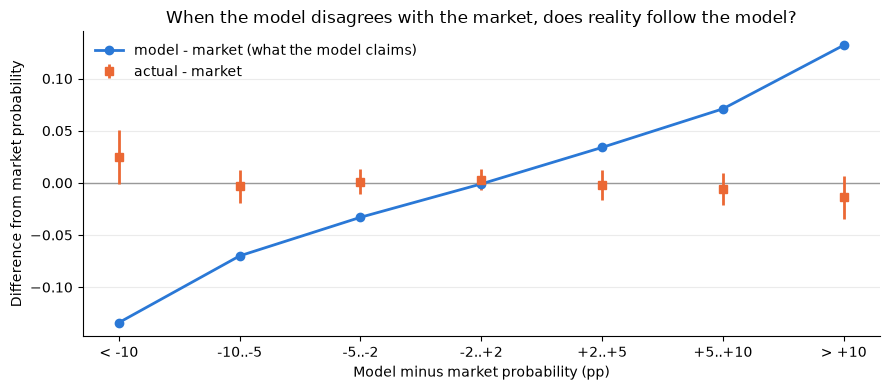

In [18]:
# Chart: actual - q per disagreement bucket, 22-23..25-26, all outcomes pooled
bt = bucket_table(main_pairs, "bucket")
x = np.arange(len(bt))
fig, ax = plt.subplots(figsize=(9, 4))
ax.axhline(0, color="#999999", linewidth=1)
ax.errorbar(x, bt["actual - q"], yerr=[bt["actual"] - bt["ci_low"], bt["ci_high"] - bt["actual"]],
            color=MARKET_COLOUR, marker="s", markersize=6, linewidth=0, elinewidth=2, label="actual - market")
ax.plot(x, bt["mean_p"] - bt["mean_q"], color=MODEL_COLOUR, marker="o", markersize=6, linewidth=2,
        label="model - market (what the model claims)")
ax.set_xticks(x, bt.index)
ax.set_xlabel("Model minus market probability (pp)")
ax.set_ylabel("Difference from market probability")
ax.set_title("When the model disagrees with the market, does reality follow the model?")
ax.legend(frameon=False)
ax.grid(alpha=0.25, axis="y")
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
fig.tight_layout()
plt.show()

## 5. Segments

Model - market log loss per segment, 22-23..25-26, with paired-bootstrap CIs.
Match-level segments use the 3-way log loss; outcome and odds-band segments use
the one-vs-rest log loss of that outcome (odds band from the average opening
price of that outcome).

With ~30 segments, one or two will look good by chance; a segment only counts
if the model is at least level with the market (diff ≤ 0), and it still has to
survive P8-03/P8-04's tune/report split.

In [19]:
segments = {}
gw = oos["Gameweek"].to_numpy()
for div in sorted(oos["Div"].unique()):
    segments[("league", div)] = compare(main & (oos["Div"] == div).to_numpy())
segments[("season stage", "GW 1-8")] = compare(main & (gw <= 8))
segments[("season stage", "GW 9+")] = compare(main & (gw > 8))
segments[("promoted", "any promoted team")] = compare(main & oos["Promoted"].to_numpy())
segments[("promoted", "promoted home side")] = compare(main & oos["HomePromoted"].to_numpy())
segments[("promoted", "promoted away side")] = compare(main & oos["AwayPromoted"].to_numpy())
segments[("promoted", "no promoted team")] = compare(main & ~oos["Promoted"].to_numpy())
segments[("promoted, GW 1-8", "any promoted team")] = compare(main & oos["Promoted"].to_numpy() & (gw <= 8))

BANDS = [(1.0, 1.5, "<1.5"), (1.5, 2.5, "1.5-2.5"), (2.5, 4.0, "2.5-4"), (4.0, 1000, ">4")]
for k, o in enumerate(OUTCOMES):
    segments[("outcome", o)] = compare_outcome(main, k)
    odds = oos[f"Avg{o}"].to_numpy()
    for lo, hi, name in BANDS:
        segments[(f"outcome x odds", f"{o} {name}")] = compare_outcome(main & (odds >= lo) & (odds < hi), k)

seg = pd.DataFrame(segments).T
seg = seg[seg["n"] > 0].drop(columns="p_model_better").astype({"n": int}).round(4)
seg["model >= market"] = seg["diff"] <= 0
seg["model better (CI)"] = seg["ci_high"] < 0
seg

n   model  market    diff  ci_low  ci_high  model >= market  model better (CI)
league           D1                  1224  0.9918  0.9710  0.0208  0.0096   0.0319            False              False
                 E0                  1520  0.9800  0.9652  0.0148  0.0047   0.0251            False              False
                 F1                  1298  0.9979  0.9785  0.0194  0.0098   0.0294            False              False
                 I1                  1520  0.9920  0.9694  0.0226  0.0135   0.0318            False              False
                 N1                  1224  0.9548  0.9382  0.0166  0.0053   0.0281            False              False
                 P1                  1224  0.9381  0.9065  0.0316  0.0215   0.0415            False              False
                 SP1                 1520  0.9844  0.9613  0.0231  0.0144   0.0321            False              False
season stage     GW 1-8              2112  0.9657  0.9377  0.0281  0.0193   0.0371            False              False
                 GW 9+               7418  0.9814  0.9623  0.0192  0.0151   0.0233            False              False
promoted         any promoted team   2664  0.9711  0.9437  0.0274  0.0200   0.0350            False              False
                 promoted home side  1404  1.0231  0.9927  0.0304  0.0199   0.0408            False              False
                 promoted away side  1404  0.9311  0.9032  0.0280  0.0179   0.0380            False              False
                 no promoted team    6866  0.9806  0.9619  0.0187  0.0143   0.0233            False              False
promoted, GW 1-8 any promoted team    590  0.9648  0.9287  0.0361  0.0182   0.0545            False              False
outcome          H                   9530  0.6103  0.5949  0.0153  0.0122   0.0184            False              False
outcome x odds   H <1.5              1609  0.5551  0.5263  0.0289  0.0206   0.0371            False              False
                 H 1.5-2.5           4167  0.6982  0.6842  0.0140  0.0093   0.0186            False              False
                 H 2.5-4             2327  0.6163  0.6055  0.0108  0.0039   0.0177            False              False
                 H >4                1427  0.4058  0.3943  0.0115  0.0048   0.0186            False              False
outcome          D                   9530  0.5604  0.5534  0.0069  0.0048   0.0089            False              False
outcome x odds   D 2.5-4             6217  0.5977  0.5940  0.0036  0.0017   0.0055            False              False
                 D >4                3313  0.4904  0.4773  0.0131  0.0084   0.0176            False              False
outcome          A                   9530  0.5463  0.5336  0.0127  0.0097   0.0156            False              False
outcome x odds   A <1.5               520  0.5846  0.5629  0.0217  0.0090   0.0343            False              False
                 A 1.5-2.5           2332  0.6957  0.6816  0.0141  0.0079   0.0202            False              False
                 A 2.5-4             3232  0.6136  0.5985  0.0151  0.0096   0.0209            False              False
                 A >4                3446  0.3763  0.3682  0.0081  0.0038   0.0124            False              False

In [20]:
# The same segments on the tuning and report seasons separately: does a 'good' segment hold up?
def seg_diff(mask_fn):
    out = {}
    for label, m in [("tune", tune), ("report", report)]:
        out[label] = mask_fn(m)["diff"]
    return out

candidates = seg[seg["diff"] <= 0.003].index
check = {}
for kind, name in candidates:
    if kind == "league":
        fn = lambda m, name=name: compare(m & (oos["Div"] == name).to_numpy())
    elif kind == "season stage":
        fn = lambda m, name=name: compare(m & ((gw <= 8) if name == "GW 1-8" else (gw > 8)))
    elif kind.startswith("promoted"):
        col = {"any promoted team": "Promoted", "promoted home side": "HomePromoted",
               "promoted away side": "AwayPromoted"}.get(name)
        if col is None:
            fn = lambda m: compare(m & ~oos["Promoted"].to_numpy())
        else:
            extra = (gw <= 8) if kind == "promoted, GW 1-8" else True
            fn = lambda m, col=col, extra=extra: compare(m & oos[col].to_numpy() & extra)
    elif kind == "outcome":
        fn = lambda m, name=name: compare_outcome(m, OUTCOMES.index(name))
    else:
        o, band = name.split(" ")
        lo, hi = next((lo, hi) for lo, hi, b in BANDS if b == band)
        odds = oos[f"Avg{o}"].to_numpy()
        fn = lambda m, o=o, lo=lo, hi=hi, odds=odds: compare_outcome(m & (odds >= lo) & (odds < hi), OUTCOMES.index(o))
    check[(kind, name)] = seg_diff(fn)
pd.DataFrame(check).T.round(4) if check else "no segment within 0.003 of the market"

'no segment within 0.003 of the market'

## 6. Baselines for later tickets

Simple strategies every P8 strategy should be compared against, flat 1 unit
per match at opening odds. All should lose roughly the margin.

In [21]:
def by_price(rule):
    def strategy(week, bankroll):
        return [single(key, rule(row), 1.0) for key, row in zip(week["MatchKey"], week.itertuples())]
    return strategy

def favourite(row):
    prices = {"H": row.oH, "D": row.oD, "A": row.oA}
    return min(prices, key=lambda s: prices[s] if pd.notna(prices[s]) else np.inf)

def random_strategy(seed=42):
    rng = np.random.default_rng(seed)
    def strategy(week, bankroll):
        return [single(key, pick, 1.0) for key, pick in zip(week["MatchKey"], rng.choice(OUTCOMES, size=len(week)))]
    return strategy

BASELINES = {
    "market favourite": lambda: by_price(favourite),
    "always home": lambda: by_price(lambda row: "H"),
    "always draw": lambda: by_price(lambda row: "D"),
    "always away": lambda: by_price(lambda row: "A"),
    "random (seed 42)": random_strategy,
    "model argmax (reference)": lambda: flat_argmax,
}

def run(strategy_factory, seasons_, source):
    result = simulate(oos[oos["Season"].isin(seasons_)], strategy_factory(), source=source)
    return summarise(result).loc["overall"]

rows = {}
for name, factory in BASELINES.items():
    for label, seasons_ in [("22-23..25-26", TEST), ("report", REPORT), ("26-27", [CURRENT])]:
        for source in ["avg", "max"]:
            s = run(factory, seasons_, source)
            rows[(name, label, source)] = {"bets": s["bets"], "hit_rate": s["hit_rate"], "avg_odds": s["avg_odds"],
                                           "roi": s["roi"], "roi_ci_low": s["roi_ci_low"],
                                           "roi_ci_high": s["roi_ci_high"], "clv": s["clv"]}
baselines = pd.DataFrame(rows).T
baselines

bets  hit_rate  avg_odds    roi  roi_ci_low  roi_ci_high   clv
market favourite         22-23..25-26 avg  9530.0      54.8     1.896  -1.71       -3.55         0.17 -0.42
                                      max  9530.0      54.8     1.953   1.15       -0.80         3.08 -1.17
                         report       avg  4728.0      53.9     1.888  -3.78       -6.37        -1.31 -0.56
                                      max  4728.0      53.8     1.943  -1.23       -3.93         1.34 -1.10
                         26-27        avg   641.0      54.8     1.858  -3.81      -12.39         5.05 -0.12
                                      max   641.0      54.6     1.919  -1.22       -9.93         7.77 -0.19
always home              22-23..25-26 avg  9530.0      43.9     2.774  -7.93      -10.63        -5.19 -0.92
                                      max  9530.0      43.9     2.927  -4.31       -7.19        -1.39 -2.01
                         report       avg  4728.0      43.1     2.754 -10.08      -13.76        -6.52 -1.15
                                      max  4728.0      43.1     2.902  -6.63      -10.52        -2.83 -1.83
                         26-27        avg   641.0      43.2     2.815  -9.06      -21.09         1.84 -0.71
                                      max   641.0      43.2     2.999  -5.29      -17.68         5.83 -0.58
always draw              22-23..25-26 avg  9530.0      25.0     4.139  -3.40       -7.01         0.08  0.57
                                      max  9530.0      25.0     4.386   1.56       -2.26         5.25  0.56
                         report       avg  4728.0      25.4     4.084  -3.23       -7.95         1.72  0.60
                                      max  4728.0      25.4     4.313   1.40       -3.60         6.62  0.79
                         26-27        avg   641.0      23.2     4.211  -7.41      -23.75        10.12 -0.80
                                      max   641.0      23.2     4.448  -2.94      -20.30        15.90 -1.20
always away              22-23..25-26 avg  9530.0      31.1     4.415 -11.92      -15.12        -8.69 -0.98
                                      max  9530.0      31.1     4.831  -7.24      -10.72        -3.75 -2.11
                         report       avg  4728.0      31.4     4.329 -10.05      -14.88        -5.32 -0.95
                                      max  4728.0      31.4     4.711  -5.40      -10.57        -0.21 -1.58
                         26-27        avg   641.0      33.5     4.180  -8.73      -20.78         3.69 -1.14
                                      max   641.0      33.5     4.611  -3.77      -16.66         9.61 -1.06
random (seed 42)         22-23..25-26 avg  9530.0      33.3     3.761  -7.82      -10.79        -4.87 -0.49
                                      max  9530.0      33.3     4.029  -3.41       -6.59        -0.23 -1.24
                         report       avg  4728.0      34.3     3.671  -6.51      -11.07        -1.78 -0.46
                                      max  4728.0      34.3     3.912  -2.30       -7.09         2.69 -0.82
                         26-27        avg   641.0      30.9     3.751 -19.16      -30.45        -7.77 -1.14
                                      max   641.0      30.9     4.041 -15.75      -27.79        -3.83 -1.39
model argmax (reference) 22-23..25-26 avg  9530.0      53.4     1.972  -2.82       -4.76        -0.99 -0.34
                                      max  9530.0      53.4     2.035   0.14       -1.88         2.05 -1.14
                         report       avg  4728.0      52.3     1.953  -5.97       -8.78        -3.35 -0.50
                                      max  4728.0      52.3     2.012  -3.21       -6.09        -0.48 -1.04
                         26-27        avg   641.0      54.1     1.953  -2.29       -8.08         3.77 -0.13
                                      max   641.0      54.1     2.020   0.92       -4.95         7.16 -0.14

In [22]:
# Compact view: ROI % [95% CI] per baseline
fmt = baselines.apply(lambda r: f"{r['roi']:+.1f} [{r['roi_ci_low']:+.1f}, {r['roi_ci_high']:+.1f}]", axis=1)
fmt.unstack([1, 2])

22-23..25-26                                   report                                    26-27                     
                                          avg                 max                  avg                 max                  avg                  max
always away               -11.9 [-15.1, -8.7]  -7.2 [-10.7, -3.8]  -10.1 [-14.9, -5.3]  -5.4 [-10.6, -0.2]   -8.7 [-20.8, +3.7]   -3.8 [-16.7, +9.6]
always draw                 -3.4 [-7.0, +0.1]   +1.6 [-2.3, +5.2]    -3.2 [-8.0, +1.7]   +1.4 [-3.6, +6.6]  -7.4 [-23.8, +10.1]  -2.9 [-20.3, +15.9]
always home                -7.9 [-10.6, -5.2]   -4.3 [-7.2, -1.4]  -10.1 [-13.8, -6.5]  -6.6 [-10.5, -2.8]   -9.1 [-21.1, +1.8]   -5.3 [-17.7, +5.8]
market favourite            -1.7 [-3.5, +0.2]   +1.1 [-0.8, +3.1]    -3.8 [-6.4, -1.3]   -1.2 [-3.9, +1.3]   -3.8 [-12.4, +5.0]    -1.2 [-9.9, +7.8]
model argmax (reference)    -2.8 [-4.8, -1.0]   +0.1 [-1.9, +2.0]    -6.0 [-8.8, -3.4]   -3.2 [-6.1, -0.5]    -2.3 [-8.1, +3.8]    +0.9 [-5.0, +7.2]
random (seed 42)           -7.8 [-10.8, -4.9]   -3.4 [-6.6, -0.2]   -6.5 [-11.1, -1.8]   -2.3 [-7.1, +2.7]  -19.2 [-30.4, -7.8]  -15.8 [-27.8, -3.8]

## Findings

**1. The model is worse than the market everywhere we can measure.** Log loss
0.978 vs 0.957 (Pinnacle→Avg opening), difference +0.021 [+0.017, +0.025].
Every league (+0.015 E0 .. +0.032 P1), every season, every outcome, every odds
band, early and late season, with and without promoted teams: all positive,
all with CI above 0. All 28 league-seasons in 22-23..25-26 are worse; 4 of
7 leagues are fractionally better in 26-27 to date, on 72-109 matches each. 26-27 to date is the closest (+0.015, CI just touching 0,
641 matches against Avg rather than Pinnacle).

**2. The model adds nothing to the market.** Tuned on 22-23/23-24, the linear
pool puts weight 0.000 on the model; the log pool gives it a = 0.09 (8% share),
and on the report seasons that blend is no better than the market
(+0.0002 [-0.0014, +0.0018]) and slightly *worse* than the market recalibrated
on its own (+0.0006 [+0.0001, +0.0011]). Fitted per season, the model weight
falls from 0.18 (22-23) to -0.17 (25-26). Whatever the model knows, the
bookmakers already price.

**3. Value betting has nothing to work with.** When the model is above the
market, the outcome happens at the market's rate or slightly less
(report seasons, d > 5pp: actual - q = -1.7pp [-3.3, 0.0], ROI -13.1%). The
bigger the disagreement, the worse the ROI. The disagreements are model error,
not market error.

**4. Calibration.** The market is a little *under*-confident (slopes 1.09-1.17;
the favourite-longshot pattern, which is why `market power` with b = 1.11 helps
marginally). The model's draw probabilities are far too flat (slope 1.60: it
barely varies them from ~25%), it under-rates strong home favourites (top bin
0.715 predicted vs 0.795 actual) and over-rates mid-range away sides (0.448 vs
0.410). These are model-improvement targets rather than betting edges.

**5. Segments where model ≥ market: none.** No league, season stage, promoted
split, outcome or odds band gets within 0.003 of the market.

**6. One after-the-fact pattern, for P8-04 to test as pre-registered, not to
trust:** backing the outcome when the model is >10pp *below* the market (a
strong favourite the model underrates). Pooled it's inconsistent (ROI -3.7%
tune, +7.1% report, -2.4% 26-27). Away favourites only were positive in all
three on small samples (n = 270 / 160 / 51); this is the model's under-rating
of strong favourites from finding 4, so it's more likely to vanish when the
model is fixed than to be a lasting edge.

**7. Baselines** (flat 1u, 22-23..25-26, ROI % [95% CI], `avg` / `max`):
market favourite -1.7 [-3.5, +0.2] / +1.1; always draw -3.4 / +1.6;
model argmax -2.8 [-4.8, -1.0] / +0.1; always home -7.9 / -4.3; random -7.8 /
-3.4; always away -11.9 / -7.2. **Backing the market favourite beats backing
the model's pick.** Any later strategy has to beat these, at `avg`, to mean
anything; `max` turns several near-zero baselines positive, which shows how
much a best-price assumption flatters a strategy.

**Recommendation for P8-03..05.** Expect P8-03 (confidence thresholds) and P8-04
(value / Kelly) to find nothing durable: they rank bets by the same model
probabilities that carry no information beyond the price. Run them as planned
so the verdict is documented (and so P8-07's multiple-testing count is honest),
but don't expand the search. The better use of effort is closing the log-loss
gap (finding 4: draw spread, strong-favourite compression), or using the market
probability as an input feature.